# Etapa 1: Análise exploratória dos dados e diagnóstico

**Disciplina:** Inteligência Artificial — Prof. Cristiane Neri Nobre
**Entrega:** 01/11/2026 | **Valor:** 2,00 pontos

Reaproveitamento do código anterior dos membros 1–4, adaptado a `treino.csv` e ao alvo binário.
As análises que estavam pendentes continuam como tarefas; não há treino de modelos nesta etapa.

| Responsável | Tarefa nesta adaptação |
|---|---|
| Membro 1 | Revisar carga, tipos e ausências da nova base; reescrever a síntese com os resultados atuais. |
| Membro 2 | Revisar distribuição normal/anomaly e justificar F1-macro, sem agrupamento em famílias. |
| Membro 3 | Revisar cardinalidade, espaços/caixa e ausências; atualizar a justificativa da codificação. |
| Membro 4 | Revisar duplicatas, conflitos, constantes e novos atributos derivados; propor comparações. |
| Membro 5 | Implementar associação de cada atributo com a classe, investigar vazamento e consolidar o diagnóstico. |

Substituir Membro 1–5 pelos nomes da equipe. Cada responsável deve executar e interpretar sua seção.
As conclusões da base antiga foram retiradas; os espaços de síntese devem ser preenchidos pela equipe.

In [1]:
from pathlib import Path
from itertools import combinations
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

project_root = Path.cwd().resolve()
if not (project_root / "data" / "treino.csv").exists():
    project_root = project_root.parent
if not (project_root / "data" / "treino.csv").exists():
    raise FileNotFoundError("Execute na raiz do projeto ou em notebooks/.")

# Leitura direta: os módulos src ainda se referem à base antiga.
CLASSES = ["normal", "anomaly"]
sns.set_theme(style="whitegrid")

## Membro 1 — Caracterização geral da base e análise dos tipos de dados

Usamos exclusivamente `treino.csv`, com cabeçalho e alvo `class`.
Preservamos todas as colunas para diagnóstico, inclusive os sinais adicionados que o Membro 5 investigará.
Não consultamos o teste e não modificamos os arquivos oficiais. Tratamentos serão comparados na etapa 2.

### 1.1 Carregamento do conjunto de treino bruto

In [2]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df_train = pd.read_csv(project_root / "data" / "treino.csv")
df_train.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,src_bytes_kb,dst_bytes_kb,total_bytes,same_srv_pct,protocolo_cod,score_ids_legado,tipo_alerta_soc,tempo_resposta_analista_min,class
0,0,tcp,http,SF,219.0000,3729,0,0,0,0,0,1.0000,0.0000,0.0000,0.0000,0,NaN,0,0.0000,0,0,0,3.0000,4.0000,NaN,0.0000,0.0000,0.0000,1.0000,0.0000,0.5000,255.0000,255.0000,1.0000,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2139,3.6416,"3,948.0000",100.0000,0,0.1760,OK,NaN,normal
1,0,tcp,finger,SF,NaN,443,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,223.0000,NaN,0.0400,0.0300,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.4326,NaN,100.0000,0,0.0670,OK,NaN,anomaly
2,0,tcp,http,SF,162.0000,29122,0,0,0,0,0,1.0000,0.0000,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,255.0000,255.0000,1.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,0.1582,28.4395,"29,284.0000",100.0000,0,0.2450,OK,NaN,normal
3,0,tcp,smtp,SF,942.0000,332,0,0,0,0,0,1.0000,0.0000,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,62.0000,173.0000,0.4200,0.0800,0.0200,0.0200,0.0000,0.0000,0.0000,0.0000,0.9199,0.3242,"1,274.0000",100.0000,0,0.2390,OK,NaN,normal
4,0,tcp,http,SF,232.0000,479,0,0,0,0,0,1.0000,NaN,0.0000,0.0000,0,0.0000,0,0.0000,0,0,0,8.0000,9.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.2200,255.0000,255.0000,1.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,0.2266,0.4678,711.0000,100.0000,0,0.2310,OK,NaN,normal


### 1.2 Dimensões e papel de cada coluna

In [3]:
COL_ROTULO = "class"
COLS_ATRIBUTOS = [c for c in df_train.columns if c != COL_ROTULO]
n_linhas, n_colunas = df_train.shape
assert n_linhas > 0
assert COL_ROTULO in df_train
assert df_train[COL_ROTULO].notna().all()
assert set(df_train[COL_ROTULO]) == set(CLASSES)
assert "id" not in COLS_ATRIBUTOS, "ID não deve ser tratado como preditor."
estrutura = pd.DataFrame({
    "Grupo": ["Atributos a investigar", "Alvo class", "Total de colunas"],
    "Quantidade": [len(COLS_ATRIBUTOS), 1, n_colunas],
})
print(f"Instâncias: {n_linhas:,}; colunas: {n_colunas}")
print(f"Uso de memória: {df_train.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
display(estrutura)

Instâncias: 69,833; colunas: 50
Uso de memória: 41.4 MB


,Grupo,Quantidade
0,Atributos a investigar,49
1,Alvo class,1
2,Total de colunas,50


In [4]:
print("Classes observadas:", sorted(df_train[COL_ROTULO].unique()))
print("Colunas:", df_train.columns.tolist())
# Não presumimos difficulty_level nem o esquema de 43 colunas do arquivo antigo.

Classes observadas: ['anomaly', 'normal']
Colunas: ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'protocolo_cod', 'score_ids_legado', 'tipo_alerta_soc', 'tempo_resposta_analista_min', 'class']


### 1.3 Mapeamento dos tipos dos atributos

Distinguimos dois níveis:
- **Tipo físico:** como o pandas armazenou a coluna (inteiro, real ou texto).
- **Tipo semântico:** o que o valor representa (categórico, binário, contagem inteira, taxa real). Isso importa porque um atributo armazenado como inteiro pode ser, na prática, uma variável binária ou categórica, e o tratamento na Etapa 2 depende dessa leitura.

Na nova base há ausentes em colunas numéricas. Como o pandas não representa `NaN` em `int64`, uma contagem com ausentes é lida como `float64`. Por isso o tipo semântico é inferido pelos **valores observados**: um real cujos valores são todos inteiros é tratado como contagem.

In [5]:
def tipo_fisico(serie: pd.Series) -> str:
    if pd.api.types.is_integer_dtype(serie):
        return "inteiro"
    if pd.api.types.is_float_dtype(serie):
        return "real"
    return "categórico (texto)"

def tipo_semantico(serie: pd.Series) -> str:
    # Heurística exploratória sobre os valores observados; ausentes são ignorados.
    if not pd.api.types.is_numeric_dtype(serie):
        return "categórico nominal"
    observados = serie.dropna()
    valores = set(observados.unique())
    if not valores:
        return "totalmente ausente"
    if len(valores) == 1:
        return "constante"
    if valores <= {0, 1}:
        return "binário (0/1)"
    if (observados == observados.round()).all():
        return "inteiro – contagem/magnitude"
    if observados.min() >= 0 and observados.max() <= 1:
        return "real – taxa em [0, 1]"
    return "real"

def inteiro_lido_como_real(serie: pd.Series) -> bool:
    observados = serie.dropna()
    return pd.api.types.is_float_dtype(serie) and bool((observados == observados.round()).all())

mapa_tipos = pd.DataFrame({
    "dtype_pandas": df_train[COLS_ATRIBUTOS].dtypes.astype(str),
    "tipo_fisico": [tipo_fisico(df_train[c]) for c in COLS_ATRIBUTOS],
    "tipo_semantico": [tipo_semantico(df_train[c]) for c in COLS_ATRIBUTOS],
    "inteiro_lido_como_real": [inteiro_lido_como_real(df_train[c]) for c in COLS_ATRIBUTOS],
    "n_ausentes": df_train[COLS_ATRIBUTOS].isna().sum(),
    "n_valores_distintos": df_train[COLS_ATRIBUTOS].nunique(),
})

# protocolo_cod tem 3 valores inteiros, mas é um código do protocolo, não uma magnitude.
print(pd.crosstab(df_train["protocol_type"].str.lower(), df_train["protocolo_cod"]))
mapa_tipos.loc["protocolo_cod", "tipo_semantico"] = "categórico codificado (inteiro)"
mapa_tipos

protocolo_cod      0      1     2
protocol_type                    
icmp               0      0  1643
tcp            56010      0     0
udp                0  12180     0


,dtype_pandas,tipo_fisico,tipo_semantico,inteiro_lido_como_real,n_ausentes,n_valores_distintos
duration,int64,inteiro,inteiro – contagem/magnitude,False,0,1590
protocol_type,str,categórico (texto),categórico nominal,False,0,6
service,str,categórico (texto),categórico nominal,False,4416,96
flag,str,categórico (texto),categórico nominal,False,4093,19
src_bytes,float64,real,inteiro – contagem/magnitude,True,27906,2114
dst_bytes,int64,inteiro,inteiro – contagem/magnitude,False,0,9147
land,int64,inteiro,binário (0/1),False,0,2
wrong_fragment,int64,inteiro,inteiro – contagem/magnitude,False,0,3
urgent,int64,inteiro,inteiro – contagem/magnitude,False,0,4
hot,int64,inteiro,inteiro – contagem/magnitude,False,0,26


In [6]:
# Resumo: quantos atributos em cada tipo físico e semântico
resumo_fisico = mapa_tipos["tipo_fisico"].value_counts().rename("qtd_atributos")
resumo_semantico = mapa_tipos["tipo_semantico"].value_counts().rename("qtd_atributos")
display(resumo_fisico.to_frame())
display(resumo_semantico.to_frame())

COLS_CATEGORICAS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "categórico (texto)"].tolist()
COLS_INTEIRAS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "inteiro"].tolist()
COLS_REAIS = mapa_tipos.index[mapa_tipos["tipo_fisico"] == "real"].tolist()
COLS_NUMERICAS = COLS_INTEIRAS + COLS_REAIS
COLS_INTEIRO_EM_REAL = mapa_tipos.index[mapa_tipos["inteiro_lido_como_real"]].tolist()

print("Categóricos:", COLS_CATEGORICAS)
print(f"Inteiros ({len(COLS_INTEIRAS)}):", COLS_INTEIRAS)
print(f"Reais ({len(COLS_REAIS)}):", COLS_REAIS)
print(f"Reais com apenas valores inteiros ({len(COLS_INTEIRO_EM_REAL)}):", COLS_INTEIRO_EM_REAL)

,qtd_atributos
tipo_fisico,
real,32
inteiro,13
categórico (texto),4


,qtd_atributos
tipo_semantico,
inteiro – contagem/magnitude,18
"real – taxa em [0, 1]",11
real,9
binário (0/1),5
categórico nominal,4
constante,1
categórico codificado (inteiro),1


Categóricos: ['protocol_type', 'service', 'flag', 'tipo_alerta_soc']
Inteiros (13): ['duration', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'num_root', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'protocolo_cod']
Reais (32): ['src_bytes', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_file_creations', 'num_access_files', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'score_ids_legado', 'tempo_resposta_analista_min']
Reais com apenas valores inteiros (12): ['src_bytes', 'logged_in', 'num_comprom

In [7]:
# Hipótese de domínio a verificar; ausentes são contados separadamente.
# A interpretação de su_attempted deve ser confirmada antes de recodificar.
BINARIOS_DOCUMENTADOS = ["land", "logged_in", "root_shell", "su_attempted",
                         "is_host_login", "is_guest_login"]

verif_binarios = pd.DataFrame({
    "valores_observados": [sorted(df_train[c].dropna().unique().tolist()) for c in BINARIOS_DOCUMENTADOS],
    "ausentes": [df_train[c].isna().sum() for c in BINARIOS_DOCUMENTADOS],
    "frequencia_valor_1": [(df_train[c] == 1).sum() for c in BINARIOS_DOCUMENTADOS],
    "dominio_0_1_respeitado": [set(df_train[c].dropna().unique()) <= {0, 1} for c in BINARIOS_DOCUMENTADOS],
}, index=BINARIOS_DOCUMENTADOS)
verif_binarios

,valores_observados,ausentes,frequencia_valor_1,dominio_0_1_respeitado
land,"[0, 1]",0,10,True
logged_in,"[0.0, 1.0]",4250,44439,True
root_shell,"[0.0, 1.0]",3880,141,True
su_attempted,"[0.0, 1.0, 2.0]",3306,16,False
is_host_login,"[0, 1]",0,2,True
is_guest_login,"[0, 1]",0,853,True


In [8]:
# Cardinalidade dos atributos categóricos (relevante para a escolha da codificação na Etapa 2)
# n_categorias_normalizadas: mesma contagem após remover espaços e uniformizar caixa (só diagnóstico).
card = pd.DataFrame({
    "n_categorias": df_train[COLS_CATEGORICAS].nunique(),
    "n_categorias_normalizadas": [df_train[c].str.strip().str.lower().nunique() for c in COLS_CATEGORICAS],
    "n_ausentes": df_train[COLS_CATEGORICAS].isna().sum(),
    "categoria_mais_frequente": [df_train[c].mode()[0] for c in COLS_CATEGORICAS],
    "pct_mais_frequente": [df_train[c].value_counts(normalize=True).iloc[0] * 100 for c in COLS_CATEGORICAS],
    "categorias_com_<10_registros": [(df_train[c].value_counts() < 10).sum() for c in COLS_CATEGORICAS],
})
card

,n_categorias,n_categorias_normalizadas,n_ausentes,categoria_mais_frequente,pct_mais_frequente,categorias_com_<10_registros
protocol_type,6,3,0,tcp,78.5073,0
service,96,67,4416,http,54.3452,29
flag,19,11,4093,SF,88.3146,6
tipo_alerta_soc,2,2,0,OK,92.7885,0


### 1.4 Valores ausentes

In [9]:
# (a) Ausentes explícitos (NaN/None) por coluna, em todas as colunas do CSV
ausentes = pd.DataFrame({
    "n_ausentes": df_train.isna().sum(),
    "pct_ausentes": df_train.isna().mean() * 100,
})
cols_com_ausentes = ausentes.index[ausentes["n_ausentes"] > 0].tolist()
print(f"Colunas com pelo menos um ausente: {len(cols_com_ausentes)} de {n_colunas}")
print(f"Total de células ausentes: {int(ausentes['n_ausentes'].sum()):,} "
      f"de {df_train.size:,} células ({ausentes['n_ausentes'].sum() / df_train.size * 100:.4f}%)")
print(f"Linhas com pelo menos um ausente: {df_train.isna().any(axis=1).sum():,} de {n_linhas:,}")
print(f"Linhas completas: {df_train.notna().all(axis=1).sum():,}")
ausentes.loc[cols_com_ausentes].sort_values("n_ausentes", ascending=False)

Colunas com pelo menos um ausente: 28 de 50
Total de células ausentes: 292,542 de 3,491,650 células (8.3783%)
Linhas com pelo menos um ausente: 69,512 de 69,833
Linhas completas: 321


,n_ausentes,pct_ausentes
tempo_resposta_analista_min,63804,91.3665
src_bytes,27906,39.9610
total_bytes,27906,39.9610
src_bytes_kb,27906,39.9610
dst_host_srv_count,27844,39.8723
dst_host_serror_rate,21393,30.6345
dst_host_same_src_port_rate,19543,27.9853
serror_rate,4734,6.7790
service,4416,6.3237
logged_in,4250,6.0859


In [10]:
# (c) Percentual de ausentes por classe. Diferenças grandes indicam ausência informativa
# (não aleatória), o que afeta a imputação e deve ser investigado pelo Membro 5 (vazamento).
pct_aus_classe = (df_train[cols_com_ausentes].isna()
                  .groupby(df_train[COL_ROTULO]).mean().T * 100)
pct_aus_classe["diferenca_pp"] = pct_aus_classe["anomaly"] - pct_aus_classe["normal"]
display(pct_aus_classe.sort_values("diferenca_pp", key=abs, ascending=False))

# Colunas com exatamente o mesmo padrão de ausência (indício de atributos derivados uns dos outros)
mascara_ausentes = df_train[cols_com_ausentes].isna()
pares_mesmo_padrao = [(a, b) for a, b in combinations(cols_com_ausentes, 2)
                      if mascara_ausentes[a].equals(mascara_ausentes[b])]
print("Pares de colunas com o mesmo padrão de ausência:", pares_mesmo_padrao)

class,anomaly,normal,diferenca_pp
tempo_resposta_analista_min,23.5352,95.5744,-72.0392
dst_host_serror_rate,44.8394,29.7533,15.0861
dst_host_same_src_port_rate,26.5261,28.0759,-1.5497
src_bytes,38.9556,40.0234,-1.0678
total_bytes,38.9556,40.0234,-1.0678
src_bytes_kb,38.9556,40.0234,-1.0678
num_file_creations,5.9573,5.3153,0.6421
count,4.7806,5.3670,-0.5864
dst_host_srv_rerror_rate,4.2167,4.7541,-0.5374
srv_diff_host_rate,5.6386,6.1091,-0.4705


Pares de colunas com o mesmo padrão de ausência: [('src_bytes', 'src_bytes_kb'), ('src_bytes', 'total_bytes'), ('same_srv_rate', 'same_srv_pct'), ('src_bytes_kb', 'total_bytes')]


In [11]:
# (b) Ausentes "disfarçados": marcadores que não viram NaN na leitura do arquivo.
# Em bases de rede é comum usar '?', '-', strings vazias ou valores negativos como "sem informação".
MARCADORES_TEXTO = {"?", "-", "", "na", "n/a", "nan", "null", "none"}
colunas_texto = COLS_CATEGORICAS + [COL_ROTULO]

marcadores = {
    c: int(df_train[c].dropna().astype(str).str.strip().str.lower().isin(MARCADORES_TEXTO).sum())
    for c in colunas_texto
}
negativos = (df_train[COLS_NUMERICAS] < 0).sum()

print("Marcadores textuais de ausência nas colunas categóricas/rótulo:", marcadores)
print("Colunas numéricas com valores negativos:", negativos[negativos > 0].to_dict())

Marcadores textuais de ausência nas colunas categóricas/rótulo: {'protocol_type': 0, 'service': 0, 'flag': 0, 'tipo_alerta_soc': 0, 'class': 0}
Colunas numéricas com valores negativos: {'duration': 358, 'src_bytes': 189, 'src_bytes_kb': 189, 'total_bytes': 73}


### 1.5 Estatísticas descritivas dos atributos numéricos

Além de média, desvio padrão e quartis, incluímos o coeficiente de variação, a assimetria e a proporção de zeros, que ajudam a justificar as propostas de transformação da Etapa 2.

In [12]:
desc = df_train[COLS_NUMERICAS].describe().T  # count, mean, std, min, 25%, 50%, 75%, max
desc["cv"] = desc["std"] / desc["mean"].replace(0, np.nan)        # dispersão relativa
desc["assimetria"] = df_train[COLS_NUMERICAS].skew()
desc["pct_zeros"] = (df_train[COLS_NUMERICAS] == 0).mean() * 100
desc.insert(0, "tipo", mapa_tipos.loc[COLS_NUMERICAS, "tipo_semantico"])
desc

,tipo,count,mean,std,min,25%,50%,75%,max,cv,assimetria,pct_zeros
duration,inteiro – contagem/magnitude,"69,833.0000","1,782.7798","225,501.2465","-1,308,801.0000",0.0000,0.0000,0.0000,"39,603,000.0000",126.4886,163.3769,87.6563
dst_bytes,inteiro – contagem/magnitude,"69,833.0000","14,833.9622","821,607.0217",0.0000,70.0000,365.0000,"2,071.0000","209,228,000.0000",55.3869,237.2351,19.5337
land,binário (0/1),"69,833.0000",0.0001,0.0120,0.0000,0.0000,0.0000,0.0000,1.0000,83.5608,83.5500,99.9857
wrong_fragment,inteiro – contagem/magnitude,"69,833.0000",0.0043,0.1099,0.0000,0.0000,0.0000,0.0000,3.0000,25.6721,26.6574,99.8325
urgent,inteiro – contagem/magnitude,"69,833.0000",0.0001,0.0156,0.0000,0.0000,0.0000,0.0000,3.0000,121.0600,147.0287,99.9914
hot,inteiro – contagem/magnitude,"69,833.0000",0.2177,2.2722,0.0000,0.0000,0.0000,0.0000,101.0000,10.4391,13.4253,98.1556
num_failed_logins,inteiro – contagem/magnitude,"69,833.0000",0.0017,0.0539,0.0000,0.0000,0.0000,0.0000,4.0000,32.1652,43.0036,99.8740
num_root,inteiro – contagem/magnitude,"69,833.0000",0.4912,31.9728,0.0000,0.0000,0.0000,0.0000,"7,468.0000",65.0874,187.5281,99.2310
num_shells,inteiro – contagem/magnitude,"69,833.0000",0.0005,0.0239,0.0000,0.0000,0.0000,0.0000,2.0000,46.4152,50.1110,99.9513
num_outbound_cmds,constante,"69,833.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,100.0000


In [13]:
# Destaques objetivos extraídos da tabela acima
print("Atributos com desvio padrão zero (constantes):",
      desc.index[desc["std"] == 0].tolist())
print("\nAtributos com mediana = 0 e Q3 = 0 (entre os valores observados; conferir pct_zeros):")
print(desc.index[(desc["50%"] == 0) & (desc["75%"] == 0)].tolist())
print("\nMaiores amplitudes (max - min):")
print((desc["max"] - desc["min"]).sort_values(ascending=False).head(5).apply(lambda v: f"{v:,.0f}"))
print("\nAtributos com |assimetria| > 10:")
print(desc.loc[desc["assimetria"].abs() > 10, "assimetria"].sort_values(ascending=False).round(1))

Atributos com desvio padrão zero (constantes): ['num_outbound_cmds']

Atributos com mediana = 0 e Q3 = 0 (entre os valores observados; conferir pct_zeros):
['duration', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'num_root', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'protocolo_cod', 'num_compromised', 'root_shell', 'su_attempted', 'num_file_creations', 'num_access_files', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'diff_srv_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']

Maiores amplitudes (max - min):
dst_bytes      209,228,000
duration        40,911,801
total_bytes     22,045,310
src_bytes       21,947,564
srv_count          512,000
dtype: str

Atributos com |assimetria| > 10:
dst_bytes_kb                  237.2000
dst_bytes                     237.2000
num_root                      187.5000
is_host_login                 186.9000
duration           

#### Valores fora do domínio esperado

Taxas (`*_rate`) deveriam estar em [0, 1] e `same_srv_pct` em [0, 100]. Pela documentação do KDD, `count` e `srv_count` vão até 511 e `dst_host_count`/`dst_host_srv_count` até 255; bytes e duração não podem ser negativos.
Por isso, parte dos atributos classificados como "real" acima é, na verdade, uma taxa ou contagem com valores inválidos. Apenas registramos; o tratamento fica para a comparação do Membro 4 na etapa 2.

In [14]:
COLS_TAXA = [c for c in COLS_NUMERICAS if c.endswith("_rate")]
LIMITES_DOMINIO = {
    **{c: (0, 1) for c in COLS_TAXA},
    "same_srv_pct": (0, 100),
    "count": (0, 511), "srv_count": (0, 511),
    "dst_host_count": (0, 255), "dst_host_srv_count": (0, 255),
    "duration": (0, np.inf), "src_bytes": (0, np.inf), "dst_bytes": (0, np.inf), "total_bytes": (0, np.inf),
}
mascaras_fora = {c: (df_train[c] < lo) | (df_train[c] > hi) for c, (lo, hi) in LIMITES_DOMINIO.items()}
fora_dominio = pd.DataFrame([
    {"atributo": c, "dominio": f"[{lo}, {hi}]", "n_fora": int(mascaras_fora[c].sum()),
     "pct_observados": 100 * mascaras_fora[c].sum() / df_train[c].notna().sum(),
     "exemplos": sorted(df_train.loc[mascaras_fora[c], c].unique().tolist())[:6]}
    for c, (lo, hi) in LIMITES_DOMINIO.items()
]).set_index("atributo")
display(fora_dominio[fora_dominio["n_fora"] > 0])
print(f"Linhas com algum valor fora do domínio: {pd.DataFrame(mascaras_fora).any(axis=1).sum():,}")

,dominio,n_fora,pct_observados,exemplos
atributo,,,,
rerror_rate,"[0, 1]",683,1.0334,"[1.5, 2.0, 5.0, 10.0]"
dst_host_same_srv_rate,"[0, 1]",670,0.9594,"[1.5, 2.0, 5.0, 10.0]"
dst_host_diff_srv_rate,"[0, 1]",623,0.9240,"[1.5, 2.0, 5.0, 10.0]"
dst_host_srv_diff_host_rate,"[0, 1]",739,1.0582,"[1.5, 2.0, 5.0, 10.0]"
dst_host_srv_rerror_rate,"[0, 1]",714,1.0731,"[1.5, 2.0, 5.0, 10.0]"
count,"[0, 511]",464,0.7019,"[550.0, 600.0, 610.0, 620.0, 650.0, 680.0]"
srv_count,"[0, 511]",507,0.7690,"[550.0, 600.0, 650.0, 700.0, 750.0, 760.0]"
dst_host_count,"[0, 255]",912,1.3845,"[260.0, 270.0, 300.0, 330.0, 340.0, 350.0]"
duration,"[0, inf]",358,0.5127,"[-1308801, -13016, -12584, -7902, -2651, -2614]"


Linhas com algum valor fora do domínio: 5,650


### 1.6 Observações estruturais para os demais membros

Verificação rápida de redundância e conflito de rótulos. Não tratamos nada aqui: os números servem de ponto de partida para quem analisar dados redundantes/inconsistentes.

In [15]:
dup_total = df_train.duplicated().sum()
# Comparação diagnóstica com todos os atributos disponíveis; não remove linhas.
grupos = df_train.groupby(COLS_ATRIBUTOS, dropna=False)[COL_ROTULO].nunique()
grupos_conflitantes = grupos[grupos > 1]
linhas_conflitantes = df_train.merge(
    grupos_conflitantes.reset_index()[COLS_ATRIBUTOS], on=COLS_ATRIBUTOS, how="inner"
)
print(f"Duplicatas exatas: {dup_total}")
print(f"Grupos com atributos idênticos e classes distintas: {len(grupos_conflitantes)}")
display(linhas_conflitantes[["protocol_type", "service", "flag", "src_bytes", "dst_bytes", COL_ROTULO]].head(12))

Duplicatas exatas: 11355
Grupos com atributos idênticos e classes distintas: 1702


,protocol_type,service,flag,src_bytes,dst_bytes,class
0,tcp,finger,SF,NaN,443,anomaly
1,tcp,http,S0,0.0000,0,normal
2,tcp,private,S0,0.0000,0,normal
3,tcp,iso_tsap,S0,0.0000,0,normal
4,icmp,eco_i,SF,8.0000,0,anomaly
5,tcp,private,S0,0.0000,0,anomaly
6,tcp,http,SF,NaN,8314,normal
7,icmp,urp_i,NaN,NaN,0,normal
8,tcp,http,SF,351.0000,3675,anomaly
9,tcp,ftp_data,S0,0.0000,0,normal


### 1.7 Síntese do Membro 1 — dimensões, tipos e completude

**Dimensões.** `treino.csv` tem **69.833 instâncias e 50 colunas**: 49 atributos e o alvo binário `class` (`normal`/`anomaly`), sem ausentes no alvo e sem coluna `id`. Dos 49 atributos, 41 são os originais do tráfego (NSL-KDD); 5 parecem derivados de outros (`src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct`, `protocolo_cod`, a confirmar pelo Membro 4) e 3 são sinais operacionais (`score_ids_legado`, `tipo_alerta_soc`, `tempo_resposta_analista_min`), cuja disponibilidade no momento da predição será avaliada pelo Membro 5. Não existe `difficulty_level` nesta base.

**Tipos.** Pelo armazenamento, são **13 inteiros, 32 reais e 4 textuais** (`protocol_type`, `service`, `flag`, `tipo_alerta_soc`). O tipo físico engana: **12 colunas reais só têm valores inteiros** (por exemplo `count`, `src_bytes`, `logged_in`) e foram lidas como `float64` apenas porque têm ausentes. Pela leitura semântica há 18 contagens/magnitudes, 11 taxas em [0, 1], 9 reais, 5 binários, 4 categóricos nominais, 1 código categórico (`protocolo_cod`, correspondência 1:1 com `protocol_type`) e 1 constante (`num_outbound_cmds`). Das 9 colunas "reais", 5 são taxas com valores acima de 1 (ver domínio abaixo). `su_attempted`, documentado como binário, assume {0, 1, 2}.

**Categóricos.** Há variações de caixa: `protocol_type` tem 6 valores, mas 3 após uniformizar caixa (`tcp`/`TCP` etc.); `service` cai de 96 para 67 e `flag` de 19 para 11. `service` tem 4.416 ausentes e `flag` 4.093. A cardinalidade real de `service` (67) é a que deve orientar a codificação (Membro 3).

**Completude.** A conclusão da base antiga não vale mais: há **292.542 células ausentes (8,38%) em 28 das 50 colunas**, e só **321 linhas (0,46%) estão completas**, o que torna inviável descartar linhas com ausentes. Não há marcadores disfarçados (`?`, `-`, vazio). As ausências formam grupos:
- `tempo_resposta_analista_min`: 91,4% ausente;
- cerca de 40%: `src_bytes`, `src_bytes_kb`, `total_bytes` (mesmo padrão de ausência, coerente com derivação) e `dst_host_srv_count`;
- 28–31%: `dst_host_serror_rate` e `dst_host_same_src_port_rate`;
- os outros 21 atributos, entre 3,5% e 6,8%.

Por classe, a ausência é praticamente igual (diferença < 1,6 p.p.) em quase todas as colunas, exceto em duas: `tempo_resposta_analista_min` falta em 95,6% das normais e 23,5% das anomalias, e `dst_host_serror_rate` em 29,8% das normais e 44,8% das anomalias. Nessas duas a ausência é **informativa**, e o próprio padrão de ausência pode revelar a classe. O tempo de resposta do analista parece existir sobretudo após um alerta do SOC, ou seja, depois da triagem. Isso é um forte indício de vazamento, a confirmar pelo Membro 5.

**Domínio e escalas.** Há valores impossíveis: negativos em `duration` (358), `src_bytes` (189) e `total_bytes` (73); taxas acima de 1 (1,5, 2, 5 e 10) em 5 colunas (`rerror_rate`, `dst_host_same_srv_rate`, `dst_host_diff_srv_rate`, `dst_host_srv_diff_host_rate`, `dst_host_srv_rerror_rate`), cerca de 1% dos valores de cada uma; e `count`/`srv_count` acima de 511 e `dst_host_count` acima de 255. Ao todo, **5.650 linhas** têm algum valor fora do domínio. As distribuições são muito assimétricas: 26 atributos têm mediana e Q3 iguais a zero, 26 têm |assimetria| > 10, e `dst_bytes` chega a 209 milhões, enquanto as taxas ficam em [0, 1].

**Observações para os demais membros.** Há 11.355 duplicatas exatas e 1.702 grupos de atributos idênticos com classes diferentes (Membro 4).

**Propostas para comparar na etapa 2** (sempre ajustadas apenas no treino de cada dobra):
1. Uniformizar caixa e espaços dos categóricos antes de codificar e tratar a ausência como categoria própria.
2. Tratar valores fora do domínio como ausentes ou recortá-los aos limites, e comparar as duas opções.
3. Imputar com a mediana, com e sem um indicador de ausência, porque parte das ausências é informativa.
4. Aplicar `log1p` em bytes, duração e contagens, seguido de padronização.
5. Remover `num_outbound_cmds` (constante).
6. Não usar os sinais operacionais até a conclusão do Membro 5.

## Membro 2 — Classes e severidade do desbalanceamento

O alvo oficial em `treino.csv` é binário (`class`: `normal` ou `anomaly`), sem subdivisão em tipos de ataque ou cinco famílias.
Analisamos a completude e a distribuição de frequências do alvo, quantificamos a razão de desbalanceamento (com e sem duplicatas exatas) e demonstramos quantitativamente por que o **F1-macro** é a métrica adequada frente à acurácia e ao F1 ponderado.

### 2.1 Classes oficiais: identificação, integridade e frequências

In [16]:
df_classes = df_train[[COL_ROTULO]].copy()
rotulos_originais = df_train[COL_ROTULO].copy(deep=True)
n_treino = len(df_classes)

# Verificações de integridade do alvo: sem ausentes, sem variações de caixa/espaço e restrito às classes oficiais
assert df_classes[COL_ROTULO].notna().all(), "Há valores ausentes no alvo class."
assert (df_classes[COL_ROTULO] == df_classes[COL_ROTULO].str.strip().str.lower()).all(), (
    "Há variações de caixa ou espaços em branco no alvo class."
)
assert set(df_classes[COL_ROTULO]) == set(CLASSES), "Classes fora do domínio oficial."
print(f"Total de registros avaliados: {n_treino:,} (0 ausentes em '{COL_ROTULO}')")
print("Classes oficiais:", CLASSES)

def tabela_frequencias(serie):
    """Conta cada categoria e calcula seu percentual sobre todas as linhas recebidas."""
    tabela = serie.value_counts(dropna=False).rename("frequencia").to_frame()
    tabela["percentual"] = 100 * tabela["frequencia"] / len(serie)
    assert tabela["frequencia"].sum() == len(serie), "Perda de registros na contagem."
    assert np.isclose(tabela["percentual"].sum(), 100), "Percentuais não somam 100%."
    return tabela


freq_rotulos = tabela_frequencias(df_classes[COL_ROTULO]).reindex(CLASSES)
display(freq_rotulos)

Total de registros avaliados: 69,833 (0 ausentes em 'class')
Classes oficiais: ['normal', 'anomaly']


,frequencia,percentual
class,,
normal,65754,94.1589
anomaly,4079,5.8411


### 2.2 Distribuição binária

Comparamos as frequências de `normal` e `anomaly` em escala linear (que evidencia a forte concentração na classe majoritária) e em escala logarítmica (que permite comparar a ordem de grandeza entre a maioria e a minoria).

In [17]:
# As mesmas cores identificam cada classe nas duas escalas.
cores_classes = dict(zip(CLASSES, sns.color_palette("colorblind", len(CLASSES))))


def plotar_distribuicao(tabela, classes, titulo, altura):
    """Mostra frequências em escalas linear e logarítmica para comparar maioria e minoria."""
    fig, eixos = plt.subplots(1, 2, figsize=(15, altura), sharey=True, layout="constrained")
    posicoes = np.arange(len(tabela))
    valores = tabela["frequencia"].to_numpy()
    cores = [cores_classes[classe] for classe in classes]
    for eixo in eixos:
        eixo.barh(posicoes, valores, color=cores)
        eixo.set_yticks(posicoes, tabela.index)
        eixo.grid(axis="y", visible=False)
        eixo.set_axisbelow(True)
    eixos[0].invert_yaxis()
    eixos[0].set_xlim(0, valores.max() * 1.55)
    eixos[0].set_title("Escala linear: concentração na classe majoritária")
    eixos[0].set_xlabel("Número de registros")
    for posicao, (quantidade, percentual) in enumerate(
        tabela[["frequencia", "percentual"]].itertuples(index=False, name=None)
    ):
        eixos[0].annotate(
            f"{quantidade:,.0f} ({percentual:.4f}%)", (quantidade, posicao),
            xytext=(5, 0), textcoords="offset points", va="center", fontsize=9,
        )
    eixos[1].set_xscale("log")
    eixos[1].set_xlim(1, valores.max() * 2.5)
    eixos[1].set_title("Escala logarítmica: comparação de ordem de grandeza")
    eixos[1].set_xlabel("Número de registros (log base 10)")
    for posicao, (quantidade, percentual) in enumerate(
        tabela[["frequencia", "percentual"]].itertuples(index=False, name=None)
    ):
        eixos[1].annotate(
            f"{quantidade:,.0f} ({percentual:.2f}%)", (quantidade, posicao),
            xytext=(5, 0), textcoords="offset points", va="center", fontsize=9,
        )
    fig.suptitle(f"{titulo} | treino.csv (n = {n_treino:,})", fontsize=14)
    plt.show()


plotar_distribuicao(freq_rotulos, freq_rotulos.index, "Classes oficiais", altura=4.5)

<Figure size 1500x450 with 2 Axes>

### 2.3 Diagnóstico quantitativo do desbalanceamento e justificativa do F1-macro

Quantificamos a razão entre a classe majoritária (`normal`) e a minoritária (`anomaly`), verificamos se essa proporção se mantém ao remover duplicatas exatas e simulamos o desempenho de um classificador trivial (que prevê apenas a classe majoritária `normal`) para evidenciar a limitação da acurácia e do F1 ponderado frente ao **F1-macro**.

In [18]:
classe_maioria = freq_rotulos["frequencia"].idxmax()
classe_minoria = freq_rotulos["frequencia"].idxmin()
qtd_maioria = int(freq_rotulos.loc[classe_maioria, "frequencia"])
qtd_minoria = int(freq_rotulos.loc[classe_minoria, "frequencia"])
pct_maioria = float(freq_rotulos.loc[classe_maioria, "percentual"])
pct_minoria = float(freq_rotulos.loc[classe_minoria, "percentual"])
razao_rotulos = qtd_maioria / qtd_minoria

print(f"Classe majoritária ({classe_maioria}): {qtd_maioria:,} registros ({pct_maioria:.4f}%)")
print(f"Classe minoritária ({classe_minoria}): {qtd_minoria:,} registros ({pct_minoria:.4f}%)")
print(f"Razão maioria/minoria ({classe_maioria}/{classe_minoria}): {razao_rotulos:,.2f}:1")

# Verificação complementar: distribuição sem duplicatas exatas (diagnóstico apenas, sem alterar df_train)
freq_sem_dup = tabela_frequencias(df_train.drop_duplicates()[COL_ROTULO]).reindex(CLASSES)
razao_sem_dup = freq_sem_dup.loc["normal", "frequencia"] / freq_sem_dup.loc["anomaly", "frequencia"]
print(f"\nSem duplicatas exatas (n = {int(freq_sem_dup['frequencia'].sum()):,}): "
      f"normal = {int(freq_sem_dup.loc['normal', 'frequencia']):,} ({freq_sem_dup.loc['normal', 'percentual']:.2f}%), "
      f"anomaly = {int(freq_sem_dup.loc['anomaly', 'frequencia']):,} ({freq_sem_dup.loc['anomaly', 'percentual']:.2f}%), "
      f"razão = {razao_sem_dup:,.2f}:1")

# Simulação de classificador trivial que prevê exclusivamente a classe majoritária ('normal')
# Para 'normal': TP = qtd_maioria, FP = qtd_minoria, FN = 0 -> Precisão = p_maj, Recall = 1.0
# Para 'anomaly': TP = 0, FP = 0, FN = qtd_minoria -> Precisão = 0.0, Recall = 0.0, F1 = 0.0
p_maj = qtd_maioria / n_treino
p_min = qtd_minoria / n_treino
f1_normal_trivial = 2 * p_maj * 1.0 / (p_maj + 1.0)
f1_anomaly_trivial = 0.0
f1_macro_trivial = (f1_normal_trivial + f1_anomaly_trivial) / 2
f1_weighted_trivial = p_maj * f1_normal_trivial + p_min * f1_anomaly_trivial

comparativo_metricas = pd.DataFrame({
    "Métrica": [
        "Acurácia global",
        "F1 — classe normal (maioria)",
        "F1 — classe anomaly (minoria)",
        "F1-weighted (ponderado pelo suporte)",
        "F1-macro (média simples entre classes)",
    ],
    "Valor no classificador trivial (só prevê normal)": [
        p_maj,
        f1_normal_trivial,
        f1_anomaly_trivial,
        f1_weighted_trivial,
        f1_macro_trivial,
    ],
    "Interpretação sob desbalanceamento 16,12:1": [
        "Aparenta 94,16% de acerto mesmo ignorando 100% dos ataques",
        "Alto (0,9699) porque recall = 1,0000 e precisão = 0,9416",
        "Zero (0,0000) porque nenhum ataque é detectado (recall = 0)",
        "Continua inflado (0,9133) pelo peso de 94,16% da classe normal",
        "Cai para 0,4850 ao atribuir peso igual (50%/50%) a cada classe",
    ],
}).set_index("Métrica")

print("\nDesempenho de um classificador trivial (sempre prevê 'normal'):")
display(comparativo_metricas)
assert df_train[COL_ROTULO].equals(rotulos_originais), "O alvo original foi alterado."

Classe majoritária (normal): 65,754 registros (94.1589%)
Classe minoritária (anomaly): 4,079 registros (5.8411%)
Razão maioria/minoria (normal/anomaly): 16.12:1

Sem duplicatas exatas (n = 58,478): normal = 54,959 (93.98%), anomaly = 3,519 (6.02%), razão = 15.62:1

Desempenho de um classificador trivial (sempre prevê 'normal'):


,Valor no classificador trivial (só prevê normal),"Interpretação sob desbalanceamento 16,12:1"
Métrica,,
Acurácia global,0.9416,"Aparenta 94,16% de acerto mesmo ignorando 100%..."
F1 — classe normal (maioria),0.9699,"Alto (0,9699) porque recall = 1,0000 e precisã..."
F1 — classe anomaly (minoria),0.0000,"Zero (0,0000) porque nenhum ataque é detectado..."
F1-weighted (ponderado pelo suporte),0.9133,"Continua inflado (0,9133) pelo peso de 94,16% ..."
F1-macro (média simples entre classes),0.4850,"Cai para 0,4850 ao atribuir peso igual (50%/50..."


### 2.4 Síntese do Membro 2 — distribuição das classes, F1-macro e balanceamento

**Quantidades, proporções e classe minoritária.** O conjunto `treino.csv` possui **69.833 registros** integralmente rotulados em duas classes oficiais, sem valores ausentes ou inconsistências de grafia em `class`: a classe majoritária é **`normal`, com 65.754 instâncias (94,1589%)**, e a classe minoritária é **`anomaly`, com 4.079 instâncias (5,8411%)**. Diferentemente da versão antiga da base, o alvo já é estritamente binário e não há decomposição em famílias ou subtipos de ataque. A razão de desbalanceamento é de **16,12:1** (aproximadamente 16 conexões normais para cada anomalia). Mesmo ao descontar as 11.355 duplicatas exatas da base (restando 58.478 registros únicos), a distribuição permanece praticamente idêntica — **54.959 `normal` (93,98%)** contra **3.519 `anomaly` (6,02%)**, razão **15,62:1** —, demonstrando que a escassez da classe `anomaly` é uma característica estrutural do problema.

**Por que usar o F1-macro em vez da acurácia isolada.** Sob a proporção 94,16% versus 5,84%, métricas globais ponderadas pelo suporte mascaram falhas graves na detecção de intrusão. Um classificador trivial que simplesmente rotule todo o tráfego como `normal` obtém **94,16% de acurácia** e **0,9133 de F1-weighted**, embora apresente **recall zero na classe `anomaly`** (100% de falsos negativos para ataques). O **F1-macro** resolve essa distorção ao calcular a média aritmética simples dos escores F1 das duas classes:

$$\text{F1}_{\text{macro}} = \frac{\text{F1}_{\text{normal}} + \text{F1}_{\text{anomaly}}}{2}$$

Nessa formulação, tanto `normal` (65.754 registros) quanto `anomaly` (4.079 registros) recebem **exatamente o mesmo peso (50% cada)**. No classificador trivial, como $\text{F1}_{\text{normal}} = 0{,}9699$ e $\text{F1}_{\text{anomaly}} = 0{,}0000$, o **F1-macro cai para 0,4850**, expondo imediatamente a incapacidade de detectar anomalias. Além disso, como o F1 de `anomaly` é a média harmônica entre precisão e recall dessa classe, maximizar o F1-macro exige não apenas recuperar os ataques (reduzindo falsos negativos), mas também controlar os falsos positivos: dado que a classe `normal` é 16,12 vezes maior, mesmo uma taxa moderada de falsos alarmes em conexões normais geraria um volume absoluto de falsos positivos capaz de derrubar a precisão de `anomaly` e, consequentemente, o F1-macro.

**Propostas de técnicas de balanceamento para a Etapa 2.** Na próxima etapa, compararemos explicitamente o **baseline sem reamostragem (`none`)** contra pelo menos duas estratégias de balanceamento sobre as mesmas dobras de validação e com o mesmo classificador de referência:
1. **Subamostragem aleatória da maioria (`RandomUnderSampler`):** reduz aleatoriamente a quantidade de registros `normal` na partição de treino de cada dobra para equilibrar a proporção com `anomaly`. Tem como vantagem reduzir o custo computacional de treinamento, mas apresenta o risco de descartar exemplos informativos do tráfego normal e aumentar a variância das fronteiras de decisão (gerando mais falsos positivos na validação).
2. **Superamostragem sintética da minoria (`SMOTE` — *Synthetic Minority Over-sampling Technique*, ou variação como `BorderlineSMOTE`):** gera novos exemplos sintéticos da classe `anomaly` por interpolação entre os $k$ vizinhos mais próximos da própria minoria, preservando 100% dos registros da classe `normal`. O ponto de atenção a investigar na Etapa 2 é o risco de sobreajuste (*overfitting*) ou de criação de amostras sintéticas invadindo a região da classe `normal` quando há sobreposição ou conflito de rótulos.

**Protocolo contra vazamento de dados (*data leakage*) na Etapa 2:**
- Utilizar validação cruzada estratificada (`StratifiedKFold`) dentro de `treino.csv` para preservar a proporção de 94,16% / 5,84% em cada dobra.
- Inserir o amostrador em uma `imblearn.pipeline.Pipeline` para que o balanceamento atue **estritamente na partição de treino de cada dobra**; as partições de validação interna e o conjunto `teste_sem_rotulo.csv` jamais devem ser balanceados ou reamostrados.
- Como o `SMOTE` calcula distâncias no espaço de atributos, aplicá-lo somente após a imputação de valores ausentes, a codificação das variáveis categóricas e a padronização numérica ajustadas dentro da respectiva dobra.

## Membro 3 — Atributos categóricos e alta cardinalidade

Revisar o código reaproveitado e acrescentar a investigação de diferenças de caixa/espaços e ausências.
Justificar a codificação de service e o tratamento de categorias desconhecidas sem ajustar encoders nesta etapa.

### 3.1 Identificação e cardinalidade

Analisamos os atributos textuais do treino, comparando suas categorias antes e depois de remover espaços nas bordas e uniformizar maiúsculas e minúsculas. A comparação usa uma cópia e preserva os valores ausentes, sem alterar a base original.

In [19]:
# Reaproveita a análise de cardinalidade para todos os categóricos do CSV.
categoricos_m3 = COLS_CATEGORICAS.copy()
dados_categoricos_m3 = df_train[categoricos_m3].copy()

cardinalidade_m3 = pd.DataFrame({"tipo": dados_categoricos_m3.dtypes.astype(str),"categorias_distintas": dados_categoricos_m3.nunique(),"valores_ausentes": dados_categoricos_m3.isna().sum(),})
cardinalidade_m3.index.name = "atributo"

display(cardinalidade_m3)

for atributo in categoricos_m3:
    categorias = sorted(dados_categoricos_m3[atributo].dropna().unique())
    print(f"\n{atributo} ({len(categorias)} categorias):")
    print(", ".join(categorias))

# Compara as categorias em uma cópia, sem alterar os dados originais.
categoricos_normalizados_m3 = dados_categoricos_m3.copy()
for atributo in categoricos_m3:
    categoricos_normalizados_m3[atributo] = (dados_categoricos_m3[atributo].str.strip().str.lower())

comparacao_m3 = pd.DataFrame({
    "categorias_originais": dados_categoricos_m3.nunique(),
    "apos_remover_espacos": [dados_categoricos_m3[c].str.strip().nunique() for c in categoricos_m3],
    "apos_espacos_e_caixa": categoricos_normalizados_m3.nunique(),
    "registros_com_espacos_nas_bordas": [(dados_categoricos_m3[c].notna() & dados_categoricos_m3[c].ne(dados_categoricos_m3[c].str.strip())).sum() for c in categoricos_m3],
    "ausentes": dados_categoricos_m3.isna().sum()
})

display(comparacao_m3)
# Confirma que a normalização preservou as posições dos ausentes.
assert categoricos_normalizados_m3.isna().equals(dados_categoricos_m3.isna())

,tipo,categorias_distintas,valores_ausentes
atributo,,,
protocol_type,str,6,0
service,str,96,4416
flag,str,19,4093
tipo_alerta_soc,str,2,0



protocol_type (6 categorias):
ICMP, TCP, UDP, icmp, tcp, udp

service (96 categorias):
IRC, IRC , X11, X11 , Z39_50, auth, auth , bgp, bgp , courier, csnet_ns, ctf, ctf , daytime, discard, domain, domain_u, domain_u , echo, eco_i, eco_i , ecr_i, ecr_i , efs, exec, exec , finger, finger , ftp, ftp , ftp_data, ftp_data , gopher, hostnames, http, http , http_2784, http_443, imap4, imap4 , iso_tsap, klogin, kshell, ldap, ldap , link, login, login , mtp, name, netbios_dgm, netbios_dgm , netbios_ns, netbios_ssn, netstat, nnsp, nntp, ntp_u, ntp_u , other, other , pm_dump, pop_2, pop_3, pop_3 , printer, private, private , red_i, remote_job, remote_job , rje, shell, smtp, smtp , sql_net, ssh, sunrpc, supdup, supdup , systat, telnet, telnet , tftp_u, tim_i, time, urh_i, urp_i, urp_i , uucp, uucp , uucp_path, uucp_path , vmnet, vmnet , whois

flag (19 categorias):
OTH, REJ, RSTO, RSTOS0, RSTR, S0, S1, S2, S3, SF, SH, rej, rsto, rstr, s0, s1, s2, s3, sf

tipo_alerta_soc (2 categorias):
ALERTA, OK

,categorias_originais,apos_remover_espacos,apos_espacos_e_caixa,registros_com_espacos_nas_bordas,ausentes
protocol_type,6,6,3,0,0
service,96,67,67,1292,4416
flag,19,19,11,0,4093
tipo_alerta_soc,2,2,2,0,0


Após padronizar a escrita, `protocol_type` passou de 6 para 3 categorias, `service` de 96 para 67 e `flag` de 19 para 11. `tipo_alerta_soc` permaneceu com 2. Foram encontrados espaços nas bordas em 1.292 registros de `service`, além de 4.416 ausentes nessa coluna e 4.093 em `flag`.

### 3.2 Distribuição dos atributos categóricos

Calculamos as frequências absolutas e percentuais após remover espaços nas bordas e uniformizar maiúsculas e minúsculas em uma cópia. Os ausentes aparecem como `NaN`, separados das categorias observadas, e os percentuais consideram todas as linhas do treino.

In [20]:
# Guarda as distribuições para reutilização nas próximas análises.
frequencias_m3 = {}

for atributo in categoricos_m3:
    tabela = categoricos_normalizados_m3[atributo].value_counts(dropna=False).rename_axis("categoria").to_frame("frequencia")
    tabela["percentual"] = (tabela["frequencia"] / len(dados_categoricos_m3) * 100)
    frequencias_m3[atributo] = tabela

    # Confere se todos os registros foram contabilizados.
    assert tabela["frequencia"].sum() == len(dados_categoricos_m3)
    assert np.isclose(tabela["percentual"].sum(), 100)
    print(f"\nDistribuição de {atributo}:")
    with pd.option_context("display.max_rows", None):
        display(tabela)


Distribuição de protocol_type:


,frequencia,percentual
categoria,,
tcp,56010,80.2056
udp,12180,17.4416
icmp,1643,2.3528



Distribuição de service:


,frequencia,percentual
categoria,,
http,36218,51.8637
domain_u,7671,10.9848
smtp,6070,8.6922
NaN,4416,6.3237
ftp_data,4269,6.1132
private,2952,4.2272
other,2173,3.1117
ftp,1097,1.5709
telnet,888,1.2716



Distribuição de flag:


,frequencia,percentual
categoria,,
sf,59278,84.8854
NaN,4093,5.8611
rej,2917,4.1771
s0,2432,3.4826
rstr,338,0.4840
s1,292,0.4181
rsto,291,0.4167
s2,109,0.1561
s3,54,0.0773



Distribuição de tipo_alerta_soc:


,frequencia,percentual
categoria,,
ok,64797,92.7885
alerta,5036,7.2115


### 3.3 Serviços frequentes, raros e cauda longa

Analisamos os dez serviços mais frequentes e os serviços com menos de 100 registros, considerados raros neste diagnóstico. O limiar de 100 registros corresponde a aproximadamente 0,14% do treino e serve apenas como critério exploratório. Os ausentes não são considerados serviços, mas os percentuais continuam calculados sobre todas as linhas do treino.

Dez serviços mais frequentes:


,frequencia,percentual
categoria,,
http,36218,51.8637
domain_u,7671,10.9848
smtp,6070,8.6922
ftp_data,4269,6.1132
private,2952,4.2272
other,2173,3.1117
ftp,1097,1.5709
telnet,888,1.2716
eco_i,601,0.8606



Serviços raros: menos de 100 registros:


,frequencia,percentual
categoria,,
time,87,0.1246
imap4,69,0.0988
x11,59,0.0845
domain,56,0.0802
uucp_path,44,0.0630
uucp,43,0.0616
ctf,42,0.0601
iso_tsap,41,0.0587
link,41,0.0587



Os 10 serviços mais frequentes representam 89.51% dos registros.
Serviços raros: 51 de 67 categorias (76.12% das categorias).
Esses serviços somam 1,410 registros (2.0191% do treino).


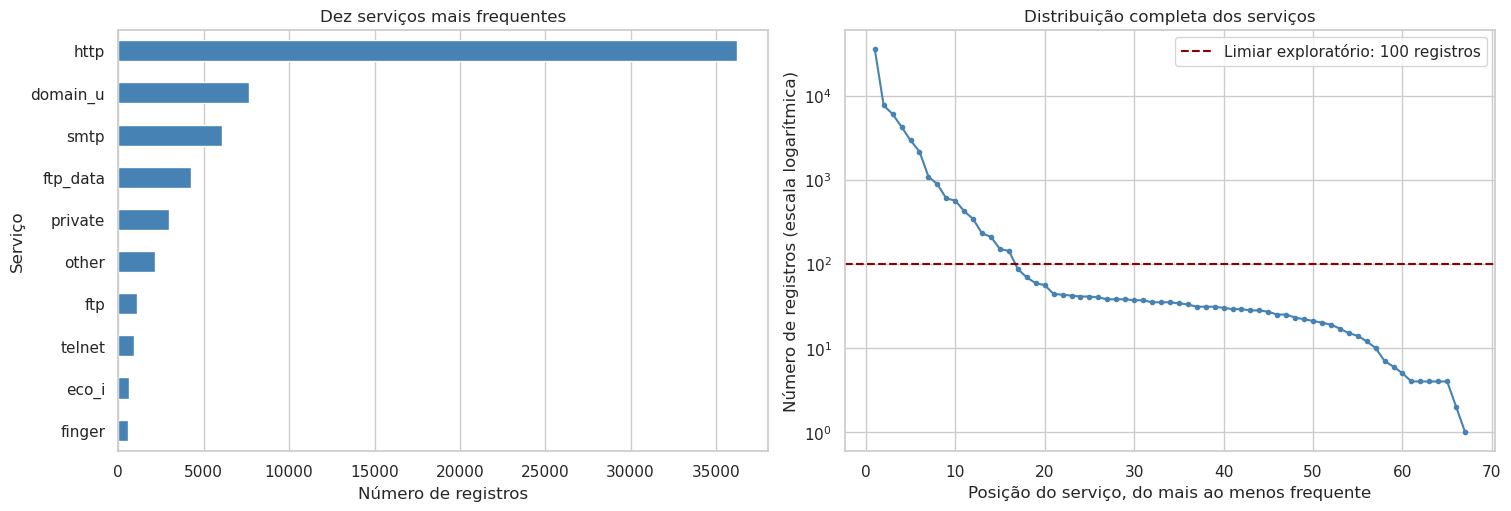

In [21]:
#Reutiliza as frequências calculadas na seção 3.2.
servicos_m3 = frequencias_m3["service"].loc[frequencias_m3["service"].index.notna()].copy()
# Ausência não é um serviço; percentuais continuam sobre todas as linhas do treino.
limiar_raridade_m3 = 100
top10_m3 = servicos_m3.head(10)
raros_m3 = servicos_m3[servicos_m3["frequencia"] < limiar_raridade_m3]

print("Dez serviços mais frequentes:")
display(top10_m3)
print(f"\nServiços raros: menos de {limiar_raridade_m3} registros:")
display(raros_m3)

#quantifica a concentração e o tamanho da cauda longa
n_servicos_m3 = len(servicos_m3)
n_raros_m3 = len(raros_m3)
registros_raros_m3 = int(raros_m3["frequencia"].sum())

print(f"\nOs 10 serviços mais frequentes representam "f"{top10_m3['percentual'].sum():.2f}% dos registros.")
print(f"Serviços raros: {n_raros_m3} de {n_servicos_m3} categorias "f"({100 * n_raros_m3 / n_servicos_m3:.2f}% das categorias).")
print(f"Esses serviços somam {registros_raros_m3:,} registros "f"({raros_m3['percentual'].sum():.4f}% do treino).")

#Visualiza os serviços dominantes e a distribuição completa.
fig, eixos = plt.subplots(1, 2, figsize=(15, 5), layout="constrained")
top10_m3["frequencia"].sort_values().plot.barh(ax=eixos[0], color="steelblue")
eixos[0].set_title("Dez serviços mais frequentes")
eixos[0].set_xlabel("Número de registros")
eixos[0].set_ylabel("Serviço")
eixos[0].grid(axis="y", visible=False)
posicoes_m3 = np.arange(1, n_servicos_m3 + 1)
eixos[1].plot(posicoes_m3,servicos_m3["frequencia"].to_numpy(),marker=".",color="steelblue",)
eixos[1].axhline(limiar_raridade_m3,color="darkred",linestyle="--",label="Limiar exploratório: 100 registros",)
eixos[1].set_yscale("log")
eixos[1].set_title("Distribuição completa dos serviços")
eixos[1].set_xlabel("Posição do serviço, do mais ao menos frequente")
eixos[1].set_ylabel("Número de registros (escala logarítmica)")
eixos[1].legend()

plt.show()

Os dez serviços mais frequentes concentram 89,51% dos registros do treino, com `http` representando 51,86%. Pelo critério de menos de 100 registros, encontramos 51 serviços raros entre as 67 categorias (76,12%). Apesar de serem a maioria das categorias, eles somam apenas 1.410 registros, ou 2,0191% do treino. Isso evidencia a cauda longa: poucos serviços concentram muitas conexões, enquanto vários aparecem pouco. Os 4.416 valores ausentes de `service` foram contabilizados separadamente e não entram como serviços raros. A baixa frequência, sozinha, não justifica remover ou agrupar essas categorias.

### 3.4 Discussão sobre alternativas de codificação e categorias desconhecidas

Antes de codificar, precisamos considerar as diferenças de escrita e os valores ausentes. Após remover espaços nas bordas e uniformizar maiúsculas e minúsculas, encontramos 3 categorias em `protocol_type`, 67 em `service`, 11 em `flag` e 2 em `tipo_alerta_soc`. No One-Hot Encoding, isso corresponde a 83 colunas sem descartar categorias, ou 85 se os ausentes de `service` e `flag` forem representados como uma categoria adicional em cada atributo. Essa quantidade não impede o uso da técnica, mas os serviços raros gerariam colunas com poucos valores 1. A presença de `tipo_alerta_soc` nesta análise não significa que ele será usado no modelo, pois sua origem e disponibilidade ainda precisam ser investigadas pelo Membro 5.

Count Encoding e Frequency Encoding mantêm uma coluna por atributo, substituindo as categorias por suas contagens ou frequências. Porém, categorias com a mesma frequência recebem o mesmo valor e perdem sua distinção. Agrupar serviços raros também pode reduzir a quantidade de categorias, mas pode juntar serviços com comportamentos diferentes. O limite de 100 registros foi usado apenas para descrever a raridade, sem aplicar agrupamentos. Os ausentes devem ser tratados separadamente, pois não representam um serviço pouco frequente.

Para categorias desconhecidas em dados futuros, o One-Hot pode deixar as colunas do atributo com valor zero quando configurado para isso. No Count/Frequency Encoding, podemos definir zero como valor padrão para categorias não encontradas. Em qualquer opção, precisamos distinguir uma categoria desconhecida de um valor ausente e aprender as categorias e frequências somente na parte de treinamento de cada divisão de validação. Nenhum codificador foi ajustado nesta análise e o teste oficial não foi consultado.

### 3.5 Síntese do Membro 3

A análise mostrou que diferenças de escrita aumentavam a quantidade de categorias: após remover espaços nas bordas e uniformizar maiúsculas e minúsculas, `protocol_type` passou de 6 para 3 categorias, `service` de 96 para 67 e `flag` de 19 para 11. `tipo_alerta_soc` permaneceu com 2 categorias. Também encontramos 4.416 ausentes em `service` e 4.093 em `flag`, que precisam ser considerados separadamente dos serviços raros. Os dez serviços mais frequentes concentram 89,51% dos registros, enquanto os 51 serviços com menos de 100 ocorrências somam apenas 2,0191% do treino.

Esses resultados mostram a importância de padronizar a escrita antes da codificação e definir como representar os ausentes. O One-Hot preserva a distinção entre categorias, enquanto Count/Frequency Encoding e agrupamento de raras oferecem alternativas com as limitações discutidas na seção 3.4. Nenhuma codificação ou remoção foi aplicada à base original. O Membro 5 pode usar `comparacao_m3`, `frequencias_m3` e `raros_m3` como apoio para investigar a associação com a classe e a possível presença de vazamento, especialmente em `tipo_alerta_soc`. Toda a análise utilizou apenas o treino.

## Membro 4 — Redundâncias, constantes e inconsistências

### 4.1 Duplicatas exatas e duplicatas de atributos

Reutilizamos os critérios de linhas completas e atributos sem classe. Aqui entram todos os atributos disponíveis.

In [22]:
COL_ROTULO_M4 = COL_ROTULO
ATRIB_M4 = COLS_ATRIBUTOS.copy()
n_treino_m4 = len(df_train)
n_dup_total = int(df_train.duplicated().sum())
n_dup_atrib_rotulo = int(df_train.duplicated(subset=ATRIB_M4 + [COL_ROTULO_M4]).sum())
mascara_dup_parcial = df_train.duplicated(subset=ATRIB_M4, keep=False)
n_linhas_dup_parcial = int(mascara_dup_parcial.sum())
n_excedentes_dup_parcial = int(df_train.duplicated(subset=ATRIB_M4).sum())
resumo_dup_m4 = pd.DataFrame({
    "criterio": ["Exata: todas as colunas", "Atributos iguais: todas as linhas dos grupos", "Atributos iguais: excedentes"],
    "n_linhas": [n_dup_total, n_linhas_dup_parcial, n_excedentes_dup_parcial],
})
resumo_dup_m4["pct_do_treino"] = 100 * resumo_dup_m4.n_linhas / n_treino_m4
display(resumo_dup_m4)

,criterio,n_linhas,pct_do_treino
0,Exata: todas as colunas,11355,16.2602
1,Atributos iguais: todas as linhas dos grupos,25788,36.9281
2,Atributos iguais: excedentes,13057,18.6975


In [23]:
# Revisão de 4.1: mesmo diagnóstico em uma cópia (categorias normalizadas) e sem derivados/operacionais.
COLS_DERIVADAS_M4 = ["src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod"]
COLS_OPERACIONAIS_M4 = ["score_ids_legado", "tipo_alerta_soc", "tempo_resposta_analista_min"]
ATRIB_ORIG_M4 = [c for c in ATRIB_M4 if c not in COLS_DERIVADAS_M4 + COLS_OPERACIONAIS_M4]

df_copia_m4 = df_train.copy()
for c in df_copia_m4[ATRIB_M4].select_dtypes(exclude="number").columns:
    df_copia_m4[c] = df_copia_m4[c].str.strip().str.lower()

def diagnostico_dup(d, cols):
    conflito = d.groupby(cols, dropna=False)[COL_ROTULO_M4].transform("nunique") > 1
    return {"duplicatas_exatas": int(d.duplicated(subset=cols + [COL_ROTULO_M4]).sum()),
            "linhas_atributos_iguais": int(d.duplicated(subset=cols, keep=False).sum()),
            "grupos_conflitantes": len(d.loc[conflito].drop_duplicates(subset=cols)),
            "linhas_conflitantes": int(conflito.sum())}

cenarios_m4 = {
    "Todos os atributos, bruto": (df_train, ATRIB_M4),
    "Todos os atributos, normalizado": (df_copia_m4, ATRIB_M4),
    "Sem derivados e operacionais, bruto": (df_train, ATRIB_ORIG_M4),
    "Sem derivados e operacionais, normalizado": (df_copia_m4, ATRIB_ORIG_M4),
}
revisao_dup_m4 = pd.DataFrame({k: diagnostico_dup(d, cols) for k, (d, cols) in cenarios_m4.items()}).T
display(revisao_dup_m4)

tamanho_grupos_m4 = df_train.loc[mascara_dup_parcial].groupby(ATRIB_M4, dropna=False).size().value_counts().sort_index()
print("Linhas por grupo de atributos iguais -> nº de grupos:", tamanho_grupos_m4.to_dict())

# Efeito de cada tratamento sobre as classes, só diagnóstico e nada é removido de df_train
efeito_trat_m4 = pd.DataFrame({
    "Base atual": df_train[COL_ROTULO_M4].value_counts(),
    "Sem duplicatas exatas": df_train.drop_duplicates()[COL_ROTULO_M4].value_counts(),
    "Uma linha por grupo de atributos": df_train.drop_duplicates(subset=ATRIB_M4)[COL_ROTULO_M4].value_counts(),
    "Sem linhas de grupos repetidos": df_train.loc[~mascara_dup_parcial, COL_ROTULO_M4].value_counts(),
}).T
efeito_trat_m4["total"] = efeito_trat_m4.sum(axis=1)
efeito_trat_m4["pct_anomaly"] = 100 * efeito_trat_m4["anomaly"] / efeito_trat_m4["total"]
display(efeito_trat_m4)

,duplicatas_exatas,linhas_atributos_iguais,grupos_conflitantes,linhas_conflitantes
"Todos os atributos, bruto",11355,25788,1702,3730
"Todos os atributos, normalizado",11355,25788,1702,3730
"Sem derivados e operacionais, bruto",11362,25798,1702,3730
"Sem derivados e operacionais, normalizado",11365,25804,1702,3730


Linhas por grupo de atributos iguais -> nº de grupos: {2: 12405, 3: 326}


class,normal,anomaly,total,pct_anomaly
Base atual,65754,4079,69833,5.8411
Sem duplicatas exatas,54959,3519,58478,6.0176
Uma linha por grupo de atributos,54112,2664,56776,4.6921
Sem linhas de grupos repetidos,42594,1451,44045,3.2944


### 4.2 Atributos iguais com classes divergentes

Reaproveitamos o agrupamento e o cálculo dos registros fora da classe majoritária de cada grupo,
agora somente para normal/anomaly. É um limite de erro de resubstituição para esses atributos,
não uma estimativa do erro em dados futuros.

In [24]:
sub_dup_m4 = df_train.loc[mascara_dup_parcial, ATRIB_M4 + [COL_ROTULO_M4]].copy()
def _maior_contagem(s):
    return int(s.value_counts().iloc[0])

grupos_m4 = (sub_dup_m4.groupby(ATRIB_M4, sort=False, dropna=False)
    .agg(n_registros=(COL_ROTULO_M4, "size"), n_rotulos=(COL_ROTULO_M4, "nunique"),
         rotulos=(COL_ROTULO_M4, lambda s: " | ".join(sorted(s.unique()))),
         maior_rotulo=(COL_ROTULO_M4, _maior_contagem)).reset_index())
conflitos_m4 = grupos_m4[grupos_m4.n_rotulos > 1].copy()
n_grupos_conflito = len(conflitos_m4)
n_linhas_conflito = int(conflitos_m4.n_registros.sum())
erro_min_rotulos = int((conflitos_m4.n_registros - conflitos_m4.maior_rotulo).sum())
print(f"Grupos conflitantes: {n_grupos_conflito}; linhas: {n_linhas_conflito}")
print(f"Erro mínimo de resubstituição para esses atributos: {erro_min_rotulos} registros")
display(conflitos_m4[["protocol_type", "service", "flag", "n_registros", "rotulos"]].head(12))  # há muitos grupos
linhas_conflito_m4 = sub_dup_m4.merge(conflitos_m4[ATRIB_M4], on=ATRIB_M4, how="inner")
afetados_m4 = linhas_conflito_m4[COL_ROTULO_M4].value_counts().rename("linhas_em_conflito").to_frame()
afetados_m4["total_no_treino"] = df_train[COL_ROTULO_M4].value_counts().reindex(afetados_m4.index)
afetados_m4["pct_da_classe"] = 100 * afetados_m4.linhas_em_conflito / afetados_m4.total_no_treino
assert len(linhas_conflito_m4) == n_linhas_conflito
display(afetados_m4)

Grupos conflitantes: 1702; linhas: 3730
Erro mínimo de resubstituição para esses atributos: 1702 registros


,protocol_type,service,flag,n_registros,rotulos
1,tcp,finger,SF,2,anomaly | normal
16,tcp,http,S0,3,anomaly | normal
20,tcp,private,S0,2,anomaly | normal
22,tcp,iso_tsap,S0,3,anomaly | normal
27,icmp,eco_i,SF,2,anomaly | normal
30,tcp,private,S0,2,anomaly | normal
32,tcp,http,SF,2,anomaly | normal
35,icmp,urp_i,NaN,3,anomaly | normal
37,tcp,http,SF,2,anomaly | normal
40,tcp,ftp_data,S0,2,anomaly | normal


,linhas_em_conflito,total_no_treino,pct_da_classe
class,,,
anomaly,1896,4079,46.4820
normal,1834,65754,2.7892


### 4.3 Atributos constantes (variância zero)

Um atributo constante tem variância zero, ou seja, apresenta o mesmo valor em todas as linhas e não ajuda a distinguir classes. Além disso, pode causar problemas em normalizações.

Verificamos isso contando os valores únicos nos atributos do CSV e calculando o desvio padrão dos numéricos. Também buscamos colunas idênticas para identificar atributos redundantes.

In [25]:
# 4.3 Atributos constantes (variância zero) e colunas idênticas entre si.

numericas_m4 = df_train[ATRIB_M4].select_dtypes(include="number").columns.tolist()

perfil_var_m4 = pd.DataFrame({
    "ausentes": df_train[ATRIB_M4].isna().sum(),
    "n_valores_unicos": df_train[ATRIB_M4].nunique(),
    "desvio_padrao": df_train[numericas_m4].std(),      # NaN nos categóricos
    "variancia": df_train[numericas_m4].var(),
})

constantes_unicos = set(perfil_var_m4.index[perfil_var_m4["n_valores_unicos"] == 1])
constantes_std = set(perfil_var_m4.index[perfil_var_m4["desvio_padrao"] == 0])
assert constantes_std <= constantes_unicos, "Divergência entre os dois critérios"
constantes_m4 = sorted(constantes_unicos)

print(f"Atributos com 1 único valor (entre valores observados): {constantes_m4}")
print(f"Atributos numéricos com desvio padrão = 0: {sorted(constantes_std)}")
if constantes_m4:
    display(pd.DataFrame({
        "valor_unico": [df_train[c].dropna().iloc[0] for c in constantes_m4],
        "n_registros": n_treino_m4,
    }, index=constantes_m4))

print("\nAtributos com menos valores distintos:")
display(perfil_var_m4.sort_values("n_valores_unicos").head(8))

# Colunas idênticas entre si (redundância exata de atributos)
pares_identicos_m4 = [(a, b) for a, b in combinations(ATRIB_M4, 2)
                      if df_train[a].equals(df_train[b])]
print(f"\nPares de colunas idênticas entre os atributos do CSV: {len(pares_identicos_m4)}")
for a, b in pares_identicos_m4:
    print(f"  {a} == {b}")

Atributos com 1 único valor (entre valores observados): ['num_outbound_cmds']
Atributos numéricos com desvio padrão = 0: ['num_outbound_cmds']


,valor_unico,n_registros
num_outbound_cmds,0,69833



Atributos com menos valores distintos:


,ausentes,n_valores_unicos,desvio_padrao,variancia
num_outbound_cmds,0,1,0.0000,0.0000
tipo_alerta_soc,0,2,NaN,NaN
root_shell,3880,2,0.0462,0.0021
is_guest_login,0,2,0.1098,0.0121
is_host_login,0,2,0.0054,0.0000
land,0,2,0.0120,0.0001
logged_in,4250,2,0.4674,0.2185
wrong_fragment,0,3,0.1099,0.0121



Pares de colunas idênticas entre os atributos do CSV: 0


### 4.4 Quase constantes, concentração em zero e domínio de su_attempted

Mantemos os limiares exploratórios de 99%, 90% e 75%. A concentração do valor dominante é calculada entre observações não ausentes, com o percentual ausente separado. Ausentes não contam como valores raros. Comparar a proporção de anomaly fora do valor dominante com a proporção atual do treino.
Verificar su_attempted sem assumir que ausência ou valor 2 deva ser convertido automaticamente para 1.

In [26]:
# 4.4 Quase constantes, concentração em zero e domínio de su_attempted.
LIMIAR_DOMINANTE_M4 = 99.0     # quase constante: >= 99% dos registros no mesmo valor
LIMIAR_CONCENTRADO_M4 = 90.0   # concentrado: entre 90% e 99% no mesmo valor
LIMIAR_ZEROS_M4 = 75.0         # apenas para listar atributos muito concentrados em zero

def perfil_concentracao(serie):
    contagem = serie.value_counts()
    if contagem.empty:
        return {"valor_dominante": np.nan, "pct_dominante": np.nan, "n_fora_do_dominante": 0}
    freq1 = int(contagem.iloc[0])
    return {
        "valor_dominante": contagem.index[0],
        "pct_dominante": 100 * freq1 / serie.notna().sum(),
        "n_fora_do_dominante": int(serie.notna().sum()) - freq1,
    }

conc_m4 = pd.DataFrame([{"atributo": c, **perfil_concentracao(df_train[c])} for c in ATRIB_M4]).set_index("atributo")
conc_m4["pct_zeros"] = (df_train[numericas_m4] == 0).mean() * 100      # NaN nos categóricos sobre todas as linhas (ausentes não contam como zero)

conc_m4["pct_ausentes"] = df_train[ATRIB_M4].isna().mean() * 100
eh_constante = (conc_m4["n_fora_do_dominante"] == 0) & (conc_m4["pct_ausentes"] == 0)
eh_q99 = conc_m4["pct_dominante"] >= LIMIAR_DOMINANTE_M4
eh_conc = conc_m4["pct_dominante"] >= LIMIAR_CONCENTRADO_M4
conc_m4["categoria"] = np.select(
    [eh_constante, eh_q99, eh_conc],
    ["constante", "quase constante (>= 99% no mesmo valor)", "concentrado (90% a 99% no mesmo valor)"],
    default="sem concentração relevante",
)

candidatos_nzv_m4 = conc_m4.index[~conc_m4["categoria"].isin(["constante", "sem concentração relevante"])].tolist()

print(conc_m4["categoria"].value_counts().to_string())
print(f"\nAtributos com >= {LIMIAR_ZEROS_M4:.0f}% de zeros: {int((conc_m4['pct_zeros'] >= LIMIAR_ZEROS_M4).sum())}")

mostrar_m4 = conc_m4[(conc_m4["categoria"] != "sem concentração relevante")
                     | (conc_m4["pct_zeros"] >= LIMIAR_ZEROS_M4)]
display(mostrar_m4.sort_values("pct_dominante", ascending=False))

eh_ataque_m4 = df_train[COL_ROTULO_M4] != "normal"
base_ataque_m4 = 100 * eh_ataque_m4.mean()
linhas_sinal = []
for c in candidatos_nzv_m4:
    fora = df_train[c].notna() & (df_train[c] != conc_m4.loc[c, "valor_dominante"])
    if not fora.any():
        continue
    rotulos_fora = df_train.loc[fora, COL_ROTULO_M4].value_counts(normalize=True)
    linhas_sinal.append({
        "atributo": c,
        "n_fora_do_dominante": int(fora.sum()),
        "pct_ataque_fora_do_dominante": 100 * eh_ataque_m4[fora].mean(),
        "rotulo_mais_comum_fora": rotulos_fora.index[0],
        "pct_desse_rotulo_fora": 100 * rotulos_fora.iloc[0],
    })
sinal_nzv_m4 = pd.DataFrame(linhas_sinal, columns=["atributo", "n_fora_do_dominante", "pct_ataque_fora_do_dominante", "rotulo_mais_comum_fora", "pct_desse_rotulo_fora"]).set_index("atributo")
print(f"\nBase inteira: {base_ataque_m4:.2f}% dos registros são anomaly.")
display(sinal_nzv_m4.sort_values("n_fora_do_dominante"))

# Domínio de su_attempted
dist_su_m4 = df_train["su_attempted"].value_counts(dropna=False).sort_index().rename("frequencia").to_frame()
dist_su_m4["percentual"] = 100 * dist_su_m4["frequencia"] / n_treino_m4
n_su_fora_dominio = int((df_train["su_attempted"].notna() & ~df_train["su_attempted"].isin([0, 1])).sum())
print("\nDistribuição de su_attempted:")
display(dist_su_m4)
print(f"Registros com su_attempted fora de {{0, 1}}: {n_su_fora_dominio}")
if n_su_fora_dominio:
    display(df_train.loc[df_train["su_attempted"].notna() & ~df_train["su_attempted"].isin([0, 1]), COL_ROTULO_M4]
            .value_counts().rename("registros_com_su_attempted_fora_do_dominio").to_frame())

categoria
sem concentração relevante                 27
quase constante (>= 99% no mesmo valor)    11
concentrado (90% a 99% no mesmo valor)     10
constante                                   1

Atributos com >= 75% de zeros: 25


,valor_dominante,pct_dominante,n_fora_do_dominante,pct_zeros,pct_ausentes,categoria
atributo,,,,,,
num_outbound_cmds,0,100.0000,0,100.0000,0.0000,constante
is_host_login,0,99.9971,2,99.9971,0.0000,quase constante (>= 99% no mesmo valor)
urgent,0,99.9914,6,99.9914,0.0000,quase constante (>= 99% no mesmo valor)
land,0,99.9857,10,99.9857,0.0000,quase constante (>= 99% no mesmo valor)
num_shells,0,99.9513,34,99.9513,0.0000,quase constante (>= 99% no mesmo valor)
su_attempted,0.0000,99.9023,65,95.1728,4.7342,quase constante (>= 99% no mesmo valor)
num_failed_logins,0,99.8740,88,99.8740,0.0000,quase constante (>= 99% no mesmo valor)
wrong_fragment,0,99.8325,117,99.8325,0.0000,quase constante (>= 99% no mesmo valor)
root_shell,0.0000,99.7862,141,94.2420,5.5561,quase constante (>= 99% no mesmo valor)



Base inteira: 5.84% dos registros são anomaly.


,n_fora_do_dominante,pct_ataque_fora_do_dominante,rotulo_mais_comum_fora,pct_desse_rotulo_fora
atributo,,,,
is_host_login,2,0.0000,normal,100.0000
urgent,6,0.0000,normal,100.0000
land,10,10.0000,normal,90.0000
num_shells,34,0.0000,normal,100.0000
su_attempted,65,0.0000,normal,100.0000
num_failed_logins,88,22.7273,normal,77.2727
wrong_fragment,117,46.1538,normal,53.8462
root_shell,141,4.2553,normal,95.7447
num_file_creations,204,2.9412,normal,97.0588



Distribuição de su_attempted:


,frequencia,percentual
su_attempted,,
0.0000,66462,95.1728
1.0000,16,0.0229
2.0000,49,0.0702
NaN,3306,4.7342


Registros com su_attempted fora de {0, 1}: 49


,registros_com_su_attempted_fora_do_dominio
class,
normal,49


### 4.5 Propostas para a etapa 2 — revisar com a equipe

A tabela abaixo reaproveita os diagnósticos para listar propostas, sem executar remoções ou correções.
Comparar tratamentos de redundância/inconsistência na etapa 2, dentro da validação no treino.
Não descartar atributos apenas por correlação exploratória ou poucos valores raros.

In [27]:
# Relações entre derivados e originais (valores e padrões de ausência).
# Cada derivado é recalculado a partir do original e comparado.
# total_bytes depende de src_bytes (ausente) e dst_bytes (sempre presente), por isso o original de referência é src_bytes.
RELACOES_M4 = [
    ("src_bytes_kb", "src_bytes", lambda d: d["src_bytes"] / 1024),
    ("dst_bytes_kb", "dst_bytes", lambda d: d["dst_bytes"] / 1024),
    ("total_bytes", "src_bytes", lambda d: d["src_bytes"] + d["dst_bytes"]),
    ("same_srv_pct", "same_srv_rate", lambda d: d["same_srv_rate"] * 100),
]
linhas_rel = []
for der, base, f in RELACOES_M4:
    ambos = df_train[der].notna() & df_train[base].notna()
    dif = (df_train.loc[ambos, der] - f(df_train.loc[ambos])).abs()
    linhas_rel.append({
        "derivado": der, "original": base, "ambos_presentes": int(ambos.sum()),
        "so_derivado_ausente": int((df_train[der].isna() & df_train[base].notna()).sum()),
        "so_original_ausente": int((df_train[der].notna() & df_train[base].isna()).sum()),
        "ambos_ausentes": int((df_train[der].isna() & df_train[base].isna()).sum()),
        "max_dif_absoluta": float(dif.max()), "n_diferentes": int((dif > 1e-9).sum()),
    })
relacoes_m4 = pd.DataFrame(linhas_rel).set_index("derivado")
display(relacoes_m4)

# protocolo_cod x protocol_type após normalizar
protocolo_norm_m4 = df_train["protocol_type"].str.strip().str.lower()
mapa_protocolo_m4 = pd.crosstab(protocolo_norm_m4, df_train["protocolo_cod"])
um_para_um_m4 = bool(((mapa_protocolo_m4 > 0).sum(axis=1) == 1).all() and ((mapa_protocolo_m4 > 0).sum(axis=0) == 1).all())
display(mapa_protocolo_m4)
print(f"Correspondência 1:1: {um_para_um_m4}; ausentes em protocol_type: {int(df_train['protocol_type'].isna().sum())}, "
      f"em protocolo_cod: {int(df_train['protocolo_cod'].isna().sum())}")

print(f"Negativos: src_bytes {int((df_train['src_bytes'] < 0).sum())}, src_bytes_kb {int((df_train['src_bytes_kb'] < 0).sum())}, "
      f"total_bytes {int((df_train['total_bytes'] < 0).sum())}")

,original,ambos_presentes,so_derivado_ausente,so_original_ausente,ambos_ausentes,max_dif_absoluta,n_diferentes
derivado,,,,,,,
src_bytes_kb,src_bytes,41927,0,0,27906,0.0000,0
dst_bytes_kb,dst_bytes,69833,0,0,0,0.0000,0
total_bytes,src_bytes,41927,0,0,27906,0.0000,0
same_srv_pct,same_srv_rate,66262,0,0,3571,0.0000,0


protocolo_cod,0,1,2
protocol_type,,,
icmp,0,0,1643
tcp,56010,0,0
udp,0,12180,0


Correspondência 1:1: True; ausentes em protocol_type: 0, em protocolo_cod: 0
Negativos: src_bytes 189, src_bytes_kb 189, total_bytes 73


In [28]:
decisoes = []
for c in constantes_m4:
    decisoes.append({"alvo": c, "proposta": "Avaliar remoção de constante",
                     "evidência": f"Um valor observado; {df_train[c].isna().sum()} ausentes. Confirmar em cada dobra."})
if n_su_fora_dominio:
    decisoes.append({"alvo": "su_attempted", "proposta": "Confirmar domínio antes de recodificar",
                     "evidência": f"{n_su_fora_dominio} valores observados fora de 0/1; ausentes separados."})
for c in candidatos_nzv_m4:
    decisoes.append({"alvo": c, "proposta": "Investigar antes de remover",
                     "evidência": f"{conc_m4.loc[c, 'pct_dominante']:.2f}% de concentração entre não ausentes."})
for der, lin in relacoes_m4.iterrows():
    decisoes.append({"alvo": der, "proposta": "Avaliar remoção do derivado (função exata do original)",
                     "evidência": f"{lin['n_diferentes']} diferenças em {lin['ambos_presentes']} pares com {lin['original']}; "
                                  f"{lin['so_derivado_ausente'] + lin['so_original_ausente']} ausentes em só um dos dois."})
if um_para_um_m4:
    decisoes.append({"alvo": "protocolo_cod", "proposta": "Avaliar remoção (código 1:1 de protocol_type)",
                     "evidência": f"Correspondência 1:1 com protocol_type normalizado; "
                                  f"{int(df_train['protocol_type'].isna().sum() + df_train['protocolo_cod'].isna().sum())} ausentes nos dois."})
decisoes.extend([
    {"alvo": "duplicatas", "proposta": "Definir tratamento e manter cópias no mesmo fold",
     "evidência": f"{n_dup_total} duplicatas exatas; {n_linhas_dup_parcial} linhas com atributos repetidos."},
    {"alvo": "classes conflitantes", "proposta": "Documentar sem inventar rótulos",
     "evidência": f"{n_grupos_conflito} grupos / {n_linhas_conflito} linhas no diagnóstico atual."},
])
decisoes_m4 = pd.DataFrame(decisoes)
display(decisoes_m4)

,alvo,proposta,evidência
0,num_outbound_cmds,Avaliar remoção de constante,Um valor observado; 0 ausentes. Confirmar em c...
1,su_attempted,Confirmar domínio antes de recodificar,49 valores observados fora de 0/1; ausentes se...
2,land,Investigar antes de remover,99.99% de concentração entre não ausentes.
3,wrong_fragment,Investigar antes de remover,99.83% de concentração entre não ausentes.
4,urgent,Investigar antes de remover,99.99% de concentração entre não ausentes.
5,hot,Investigar antes de remover,98.16% de concentração entre não ausentes.
6,num_failed_logins,Investigar antes de remover,99.87% de concentração entre não ausentes.
7,num_compromised,Investigar antes de remover,97.99% de concentração entre não ausentes.
8,root_shell,Investigar antes de remover,99.79% de concentração entre não ausentes.
9,su_attempted,Investigar antes de remover,99.90% de concentração entre não ausentes.


### 4.6 Síntese do Membro 4

**Duplicatas e conflitos:** O treino possui 11.355 duplicatas exatas (16,26% da base). Além disso, 1.702 grupos apresentam os mesmos atributos, mas classes diferentes, totalizando 3.730 linhas. Isso mostra que alguns registros são indistinguíveis mesmo tendo rótulos diferentes, o que dificulta a classificação de anomalias. Por isso, não foram alterados rótulos.

**Constantes e derivados:** A coluna num_outbound_cmds contém apenas zeros e pode ser removida. As cinco colunas derivadas repetem informações já presentes nos atributos originais, sem recuperar valores ausentes. Recomenda-se avaliar sua remoção na próxima etapa.

**Valores raros e inconsistências:** Muitos atributos apresentam valores concentrados em poucas categorias, e 25 possuem pelo menos 75% de zeros. Alguns valores raros aparecem com maior frequência em anomalias, mas não há dados suficientes para justificar a exclusão desses atributos. Também foram encontrados 49 valores iguais a 2 em su_attempted, embora o atributo seja documentado como binário. Esses casos devem ser investigados sem alterar os dados antecipadamente.

## Membro 5 — Investigação de vazamento e diagnóstico final

Esta parte ainda não estava implementada no notebook antigo e permanece a cargo do responsável.

1. Investigar a associação de **cada atributo** com class antes de qualquer modelo: numéricos, categóricos e padrões de ausência. Registrar constantes e limitações das medidas.
2. Analisar `score_ids_legado`, `tipo_alerta_soc` e `tempo_resposta_analista_min`: origem, momento em que estariam disponíveis e possível dependência da classificação/triagem. Correlação não comprova vazamento; justificar qualquer exclusão.
3. Revisar correlação entre atributos e relações determinísticas com o Membro 4. Não procurar difficulty_level se não existe no CSV.
4. Consolidar as cinco análises e o plano de validação no treino. Não acessar o teste sem rótulos para escolher tratamentos ou tentar reconstruir seu gabarito.

In [29]:
# TODO Membro 5: investigar os sinais operacionais adicionados e seus padrões de ausência.
# Registrar evidências e hipóteses de disponibilidade, sem exclusão automática por correlação.

In [30]:
# TODO Membro 5: calcular associação de TODOS os atributos com class.
# Usar medidas adequadas a numéricos/categóricos e revisar redundâncias com o Membro 4.

### Sintese do Membro 5 e Diagnostico Consolidado da Etapa 1
*[Espaco para o Membro 5 redigir a conclusao sobre prevencao de data leakage e consolidar o diagnostico geral da equipe para entrega]*